Laboratorul 3 – PCA și K-Means Clustering

Partea 1 – Date, PCA și scalare

    Încărcarea dataset-ului curățat, encoding pentru variabilele categorice și min-max scaling.
    PCA pentru 98% din varianță: varianța explicată de fiecare componentă și numărul de features rămase.
    Numărul de componente necesare pentru 95%, 90% și 80% din varianță, cu graficul variației cumulate.
    Funcția de preprocesare cu standardizare și logaritmare, folosită și în celelalte părți.
    Funcția pentru profilul clusterelor, folosită după K-Means (Partea 2).

In [1]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_RAW = ROOT / "data" / "raw"              # AmesHousing.csv (fisierul original, nu e in Git)
DATA_PROCESSED = ROOT / "data" / "processed"  # df.csv, df_fe.csv (generate de notebook-uri, nu sunt in Git)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "src"))         # ca sa functioneze `from lab3_common import ...`

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from lab3_common import preprocess, cluster_profile

df = pd.read_csv(DATA_PROCESSED / "df.csv")

print("Dimensiunea dataset-ului:", df.shape)
display(df.head())

Dimensiunea dataset-ului: (2930, 83)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,Has_Garage
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,NaN,NaN,NaN,0,5,2010,WD,Normal,215000,1
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000,1
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000,1
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,NaN,NaN,NaN,0,4,2010,WD,Normal,244000,1
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900,1


-Încărcarea dataset-ului curățat

Este încărcat fișierul `df.csv`, dataset-ul Ames Housing curățat în `01_EDA.ipynb` (2930 de locuințe, 83 de coloane). Variabila `SalePrice` rămâne în `df` pentru etapele următoare, dar nu este folosită ca feature la clustering.

In [3]:
X_scaled, y, pipeline = preprocess(df, scaling="minmax", log=False)

print("Dimensiunea după encoding și scalare:", X_scaled.shape)
print("Valoare minimă / maximă:", X_scaled.to_numpy().min(), "/", X_scaled.to_numpy().max())
print("Valori lipsa:", X_scaled.isna().sum().sum())
display(X_scaled.head())

Dimensiunea după encoding și scalare: (2930, 295)
Valoare minimă / maximă: 0.0 / 1.0
Valori lipsa: 0


,Exter Qual,Exter Cond,Bsmt Qual,Bsmt Cond,Heating QC,Kitchen Qual,Fireplace Qu,Garage Qual,Garage Cond,Pool QC,...,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Yr Sold,Has_Garage
0,0.333333,0.5,0.6,0.8,0.25,0.50,0.8,0.6,0.6,0.0,...,0.354839,0.147472,0.083558,0.0,0.0,0.000000,0.0,0.000000,1.0,1.0
1,0.333333,0.5,0.6,0.6,0.50,0.50,0.0,0.6,0.6,0.0,...,0.490591,0.098315,0.000000,0.0,0.0,0.208333,0.0,0.000000,1.0,1.0
2,0.333333,0.5,0.6,0.6,0.50,0.75,0.0,0.6,0.6,0.0,...,0.209677,0.275983,0.048518,0.0,0.0,0.000000,0.0,0.735294,1.0,1.0
3,0.666667,0.5,0.6,0.6,1.00,1.00,0.6,0.6,0.6,0.0,...,0.350806,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,1.0,1.0
4,0.333333,0.5,0.8,0.6,0.75,0.50,0.6,0.6,0.6,0.0,...,0.323925,0.148876,0.045822,0.0,0.0,0.000000,0.0,0.000000,1.0,1.0


-Encoding și min-max scaling

Funcția `preprocess()` din `src/lab3_common.py` folosește `build_features()` din `common.py` (aceleași completări de valori lipsa ca în Lab 2): calitățile au encoding ordinal, categoriile nominale au encoding one-hot, iar coloanele `SalePrice`, `Order` și `PID` nu intră în features. Apoi toate coloanele sunt aduse în intervalul [0, 1] cu `MinMaxScaler`.

După encoding, dataset-ul are 295 de features (față de 80 de coloane inițiale), toate între 0 și 1 și fără valori lipsa.

In [4]:
pca_98 = PCA(n_components=0.98, svd_solver="full").fit(X_scaled)

n_features = X_scaled.shape[1]
n_98 = pca_98.n_components_

var_table = pd.DataFrame({
    "PC": [f"PC{i + 1}" for i in range(n_98)],
    "varianta_explicata": pca_98.explained_variance_ratio_,
    "varianta_cumulata": np.cumsum(pca_98.explained_variance_ratio_),
})

print(f"Features înainte de PCA: {n_features}")
print(f"Componente principale pentru 98% din varianță: {n_98}")
print(f"Varianța păstrată: {pca_98.explained_variance_ratio_.sum():.4f}")
display(var_table.head(10))

Features înainte de PCA: 295
Componente principale pentru 98% din varianță: 142
Varianța păstrată: 0.9800


,PC,varianta_explicata,varianta_cumulata
0,PC1,0.114148,0.114148
1,PC2,0.072140,0.186289
2,PC3,0.045195,0.231483
3,PC4,0.035727,0.267210
4,PC5,0.030675,0.297885
5,PC6,0.028514,0.326399
6,PC7,0.024300,0.350699
7,PC8,0.022867,0.373566
8,PC9,0.022215,0.395781
9,PC10,0.020657,0.416439


-PCA pentru 98% din varianță

`PCA(n_components=0.98)` păstrează cel mai mic număr de componente care explică împreună cel puțin 98% din varianța datelor. Tabelul `var_table` conține varianța explicată de fiecare dintre aceste componente (`explained_variance_ratio_`) și varianța cumulată; mai sus sunt afișate primele 10.

Dataset-ul se reduce de la 295 de features la 142 de componente principale, deci rămân aproximativ 48% din dimensiuni. Prima componentă explică 11,4% din varianță, a doua 7,2%, iar a treia 4,5%. Restul componentelor explică fiecare mai puțin de 4%, așa că varianța este răspândită pe multe componente.

,prag_varianta,componente_necesare
0,98%,142
1,95%,106
2,90%,79
3,80%,50


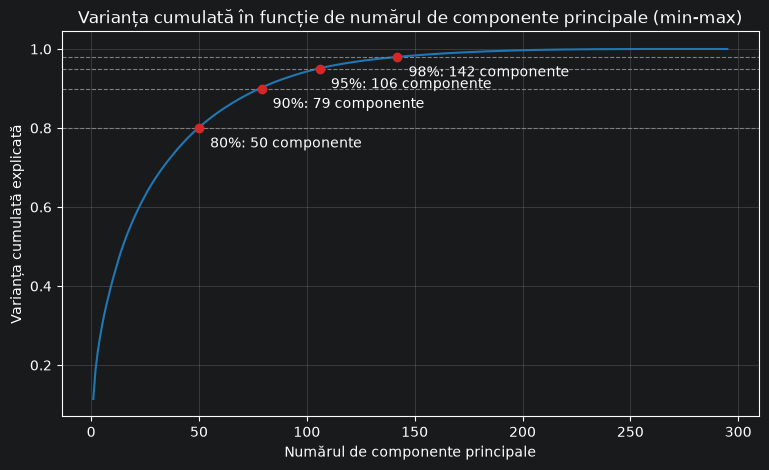

In [5]:
pca_full = PCA(svd_solver="full").fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

thresholds = [0.98, 0.95, 0.90, 0.80]
n_components = {t: int(np.searchsorted(cumulative, t) + 1) for t in thresholds}

display(pd.DataFrame({
    "prag_varianta": [f"{t:.0%}" for t in thresholds],
    "componente_necesare": [n_components[t] for t in thresholds],
}))

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative, color="tab:blue")
for t in thresholds:
    plt.axhline(t, color="gray", linestyle="--", linewidth=0.8)
    plt.plot(n_components[t], t, "o", color="tab:red")
    plt.annotate(f"{t:.0%}: {n_components[t]} componente", (n_components[t], t),
                 textcoords="offset points", xytext=(8, -14))
plt.xlabel("Numărul de componente principale")
plt.ylabel("Varianța cumulată explicată")
plt.title("Varianța cumulată în funcție de numărul de componente principale (min-max)")
plt.grid(alpha=0.3)
plt.show()

-Praguri de varianță și varianța cumulată

Numărul de componente necesare pentru fiecare prag este primul index la care varianța cumulată atinge pragul respectiv. Rezultatele sunt: 142 de componente pentru 98%, 106 pentru 95%, 79 pentru 90% și 50 pentru 80%.

Graficul arată că varianța crește repede la început și tot mai lent spre final: primele 50 de componente acoperă 80% din varianță, dar ultimele 36 de componente (de la 106 la 142) aduc doar 3 puncte procentuale. Aceste patru praguri sunt cele pentru care se vor antrena modelele K-Means în Partea 2.

In [6]:
rows = []
for scaling in ["minmax", "standard"]:
    for log in [False, True]:
        Xs, _, pipe = preprocess(df, scaling=scaling, log=log)
        cum = np.cumsum(PCA(svd_solver="full").fit(Xs).explained_variance_ratio_)
        row = {"scalare": scaling, "logaritmare": log, "features": Xs.shape[1],
               "coloane_logaritmate": len(pipe["log"].log_cols_) if log else 0}
        for t in thresholds:
            row[f"componente_{t:.0%}"] = int(np.searchsorted(cum, t) + 1)
        rows.append(row)

display(pd.DataFrame(rows))

,scalare,logaritmare,features,coloane_logaritmate,componente_98%,componente_95%,componente_90%,componente_80%
0,minmax,False,295,0,142,106,79,50
1,minmax,True,295,19,143,107,80,51
2,standard,False,295,0,210,187,162,125
3,standard,True,295,19,208,186,161,124


-Funcția de preprocesare: min-max vs. standardizare, cu și fără logaritmare

`preprocess(df, scaling, log)` poate produce toate cele patru variante: `scaling="minmax"` sau `"standard"` (normalizare, medie 0 și abatere standard 1) și `log=False` sau `True`. Logaritmarea (`log1p`) se aplică doar pe coloanele numerice nenegative, cu multe valori distincte și asimetrie pozitivă mare (skew > 0.75), adică 19 coloane, precum `Lot Area`, `Gr Liv Area` și `Total Bsmt SF`. Coloanele cu puține valori distincte, anii și variabilele one-hot nu sunt logaritmate.

Tabelul arată efectul asupra PCA: numărul de componente necesare pentru fiecare prag. Efectele observate:

- Standardizarea cere mult mai multe componente decât min-max (de exemplu 210 față de 142 pentru 98%, și 125 față de 50 pentru 80%). Explicația probabilă: la standardizare fiecare feature are varianța 1, deci și variabilele one-hot rare contribuie la fel ca restul și varianța se răspândește pe mai multe direcții. La min-max, features-urile cu valori rare sau cu outlieri au varianță mică, iar varianța este concentrată în mai puține componente.
- Logaritmarea schimbă foarte puțin numărul de componente (diferență de cel mult 2 componente). Efectul ei se vede mai degrabă în forma distribuțiilor și în clusterele obținute, deci comparația se continuă în Partea 2, după K-Means.

-Profilul clusterelor

Funcția `cluster_profile(df, labels)` din `src/lab3_common.py` va fi folosită după K-Means (Partea 2). Primește dataset-ul curățat (cu valorile originale, nescalate) și etichetele clusterelor, în aceeași ordine ca rândurile din `df`, și întoarce pentru fiecare cluster numărul de case și media fiecărei coloane numerice. Se apelează astfel:

`profile = cluster_profile(df, labels)`